# Project 1 - Wholesale Customers: Segmenting by Spending Behaviour

**Course:** Data Mining, Modeling and Analytics (Assignment 2)

**Task:** Segment wholesale customers by spending behaviour and recommend how the distributor
could serve each segment differently.

**Structure**: data understanding => justified preparation => **cluster tendency** =>
partitioning vs. hierarchical vs. density-based clustering (quality *and* interpretability) =>
named segments with service recommendations.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, fcluster, cophenet, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.utils import resample

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)


## 1. Data Loading


In [2]:
df = pd.read_csv("data/wholesale-customers.csv")
print("Shape:", df.shape)
df.head()


Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
df.info()
print("\nMissing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicatessen      440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Missing values: 0
Exact duplicate rows: 0


## 2. Exploratory Data Analysis & Data Report

### 2.1 Structure
`Channel` and `Region` are integer-coded **nominal** variables (per the data README), not
quantities. We decode them for reporting. The six spend columns are the behavioural features.


In [4]:
SPEND = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]
CHANNEL = {1: "Horeca", 2: "Retail"}
REGION = {1: "Lisbon", 2: "Oporto", 3: "Other"}
df["Channel_name"] = df["Channel"].map(CHANNEL)
df["Region_name"] = df["Region"].map(REGION)

print(df["Channel_name"].value_counts(), "\n")
print(df["Region_name"].value_counts(), "\n")
print(pd.crosstab(df["Region_name"], df["Channel_name"]))


Channel_name
Horeca    298
Retail    142
Name: count, dtype: int64 

Region_name
Other     316
Lisbon     77
Oporto     47
Name: count, dtype: int64 

Channel_name  Horeca  Retail
Region_name                 
Lisbon            59      18
Oporto            28      19
Other            211     105


### 2.2 Spend distributions


In [5]:
desc = df[SPEND].describe().T
desc["skew"] = df[SPEND].skew()
desc


,count,mean,std,min,25%,50%,75%,max,skew
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0,2.561323
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0,4.053755
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0,3.587429
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0,5.907986
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0,3.631851
Delicatessen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0,11.151586


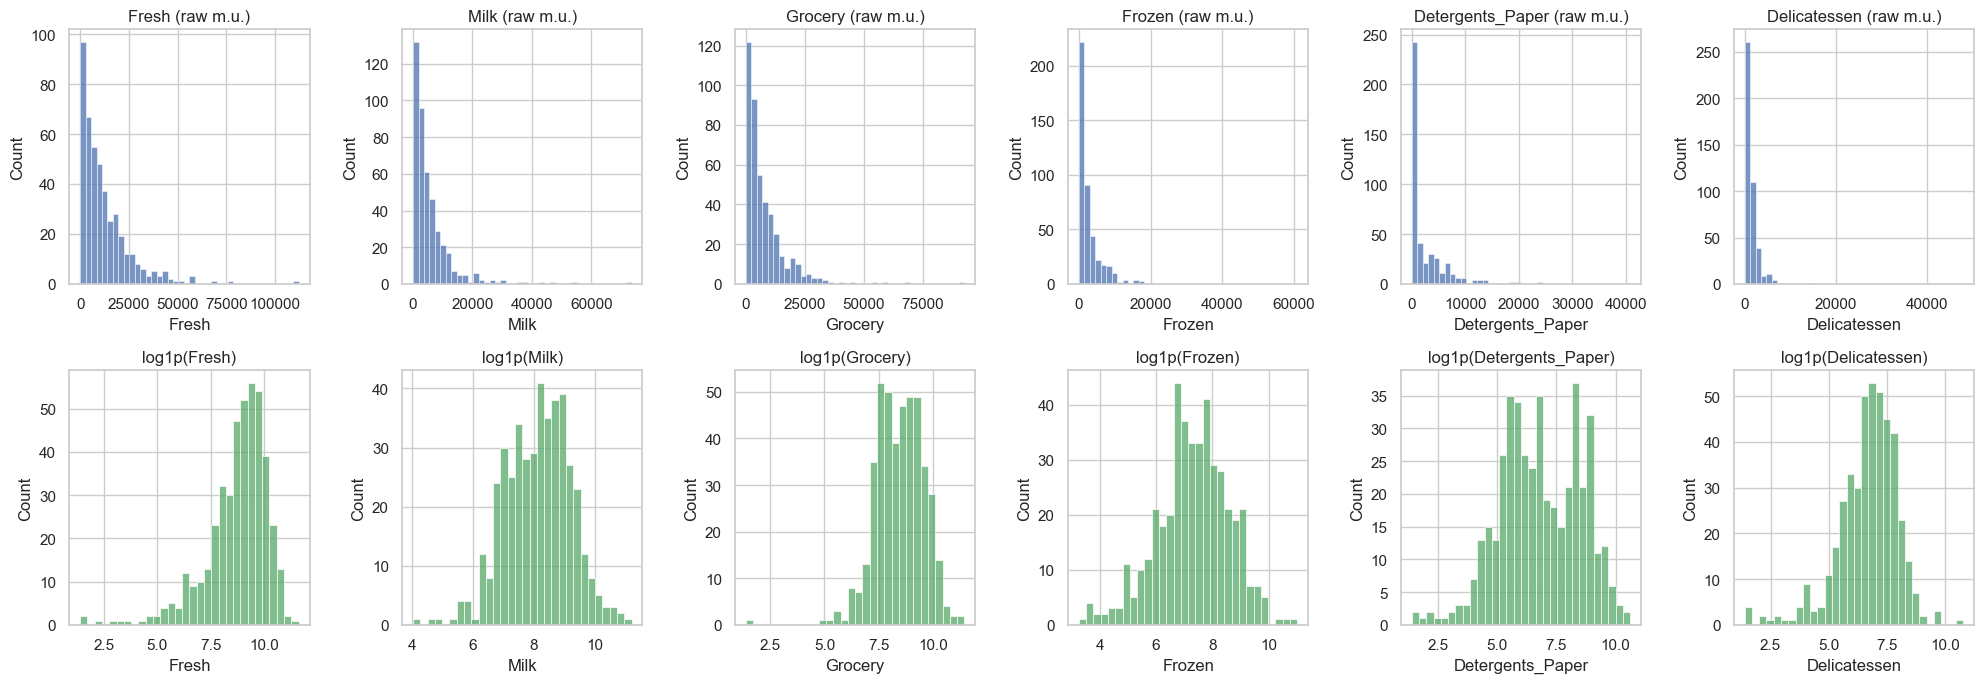

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for i, col in enumerate(SPEND):
    sns.histplot(df[col], bins=40, ax=axes[0, i])
    axes[0, i].set_title(f"{col} (raw m.u.)")
    sns.histplot(np.log1p(df[col]), bins=30, ax=axes[1, i], color="#55A868")
    axes[1, i].set_title(f"log1p({col})")
plt.tight_layout()
plt.show()


**Observations:** every spend column is strongly right-skewed, with means far above medians and a handful of very large accounts. Distance-based clustering on the raw scale would be dominated by these few extreme customers and by the categories with the largest absolute spend. 

The bottom row shows that a `log1p` transform brings all six columns to roughly symmetric, comparable shapes. This is the justification for the transform in Section 3.

### 2.3 Correlation between categories


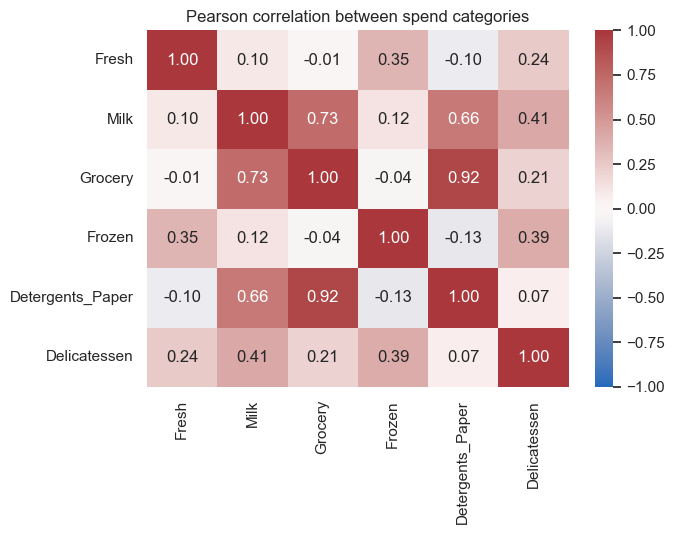

In [7]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df[SPEND].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation between spend categories")
plt.tight_layout()
plt.show()


`Grocery`, `Detergents_Paper` and `Milk` form a tightly correlated block (Grocery–Detergents r ~ 0.92, Grocery–Milk ~ 0.73, Milk–Detergents ~ 0.66) which is the signature of a *retail-shop* basket. `Fresh` and `Frozen` are essentially uncorrelated with that block and mildly correlated with each other. This suggests at least one dominant axis of variation (grocery/household vs. fresh), which we expect clustering to recover.

### 2.4 Spend by sales channel (external context, not a clustering input)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Channel_name,,,,,,
Horeca,9581.5,2157.0,2684.0,2057.5,385.5,821.0
Retail,5993.5,7812.0,12390.0,1081.0,5614.5,1350.0


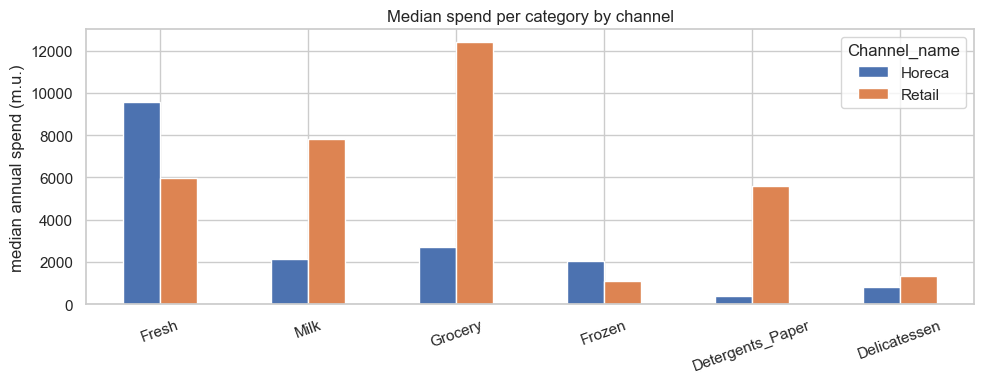

In [8]:
median_by_channel = df.groupby("Channel_name")[SPEND].median()
display(median_by_channel)

fig, ax = plt.subplots(figsize=(10, 4))
median_by_channel.T.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("median annual spend (m.u.)")
ax.set_title("Median spend per category by channel")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


Horeca customers spend most on `Fresh` and `Frozen`; Retail customers on `Grocery`, `Milk` and
`Detergents_Paper`. We deliberately do **not** feed `Channel`/`Region` into the clustering
(Section 3)

## 3. Data Preparation (with justification)

1. **Feature set = the six spend columns only.** `Channel` and `Region` are nominal codes; putting them into a Euclidean-distance algorithm would treat "Region 3 vs 1" as twice the distance of "2 vs 1", which is meaningless. They are held out as *profiling variables*.
2. **`log1p` transform** of every spend column (Section 2.2): removes the heavy right skew so a few   extreme accounts do not dominate distances, and makes "10x more spend" count the same in every category.
3. **Standardize** (`StandardScaler`) after the log, so all six categories contribute equally regardless of their typical magnitude (`Fresh` median 8.5k vs `Delicatessen` median ~1k).
4. **Outliers are kept.** They are real, large customers which is exactly the kind of account a distributor cares about. Density-based clustering will flag them as "noise", which we treat as a finding, not an error.
5. **PCA to 2-D for visualization only** (not used for clustering).


In [9]:
X_log = np.log1p(df[SPEND])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
X = pd.DataFrame(X, columns=SPEND)

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
X_pca = pca.transform(X)
print("PCA explained variance ratio (2 components):", pca.explained_variance_ratio_.round(3),
      "-> total", pca.explained_variance_ratio_.sum().round(3))
loadings = pd.DataFrame(pca.components_.T, index=SPEND, columns=["PC1", "PC2"])
loadings.round(3)


PCA explained variance ratio (2 components): [0.441 0.272] -> total 0.713


,PC1,PC2
Fresh,-0.105,0.590
Milk,0.542,0.133
Grocery,0.571,-0.006
Frozen,-0.138,0.590
Detergents_Paper,0.551,-0.071
Delicatessen,0.214,0.530


## 4. Cluster Tendency

Clustering algorithms always return clusters — even on uniform noise — so we first test whether
the data has any cluster structure to find.

**Hopkins statistic** compares nearest-neighbour distances of real points to those of uniformly
random points in the same bounding box. H ~ 0.5 means the data is indistinguishable from uniform
(no tendency); H => 1 means strongly clustered. We also run it on a genuinely uniform control of
the same shape to calibrate.


In [10]:
def hopkins(X, sample_frac=0.1, random_state=0):
    X = np.asarray(X)
    rng = np.random.default_rng(random_state)
    n, d = X.shape
    m = max(10, int(sample_frac * n))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    idx = rng.choice(n, m, replace=False)
    w = nn.kneighbors(X[idx], n_neighbors=2)[0][:, 1]          # real point -> nearest other real point
    U = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, d))
    u = nn.kneighbors(U, n_neighbors=1)[0][:, 0]               # uniform point -> nearest real point
    return u.sum() / (u.sum() + w.sum())

h_real = [hopkins(X, random_state=s) for s in range(20)]
rng = np.random.default_rng(RANDOM_STATE)
X_uniform = rng.uniform(X.min(axis=0), X.max(axis=0), size=X.shape)
h_ctrl = [hopkins(X_uniform, random_state=s) for s in range(20)]

print(f"Hopkins (real data)      : {np.mean(h_real):.3f} +/- {np.std(h_real):.3f}  over 20 repeats")
print(f"Hopkins (uniform control): {np.mean(h_ctrl):.3f} +/- {np.std(h_ctrl):.3f}")


Hopkins (real data)      : 0.797 +/- 0.015  over 20 repeats
Hopkins (uniform control): 0.503 +/- 0.012


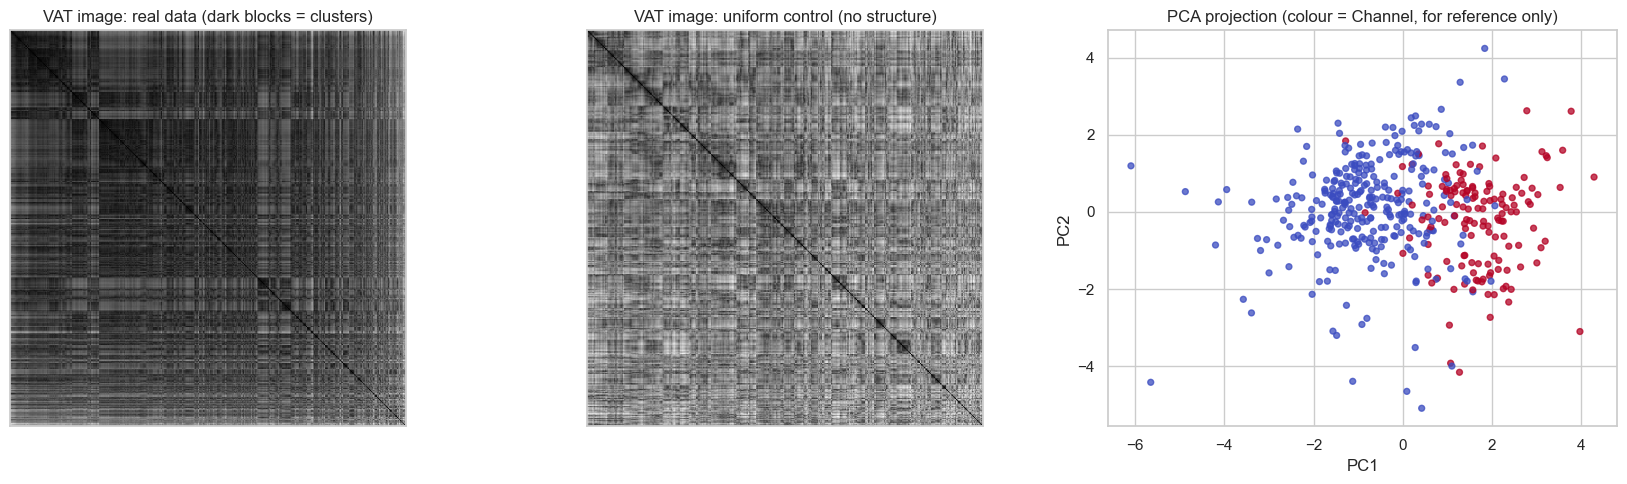

In [11]:
def vat_order(D):
    # Visual Assessment of cluster Tendency: Prim-style ordering of the dissimilarity matrix
    n = D.shape[0]
    order = [int(np.argmax(D.max(axis=1)))]
    remaining = np.ones(n, dtype=bool)
    remaining[order[0]] = False
    for _ in range(n - 1):
        idx = np.where(remaining)[0]
        j = idx[np.argmin(D[np.ix_(order, idx)].min(axis=0))]
        order.append(int(j))
        remaining[j] = False
    return np.array(order)

D = squareform(pdist(X))
order = vat_order(D)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].imshow(D[np.ix_(order, order)], cmap="gray")
axes[0].set_title("VAT image: real data (dark blocks = clusters)")
axes[0].set_xticks([]); axes[0].set_yticks([])

D_u = squareform(pdist(X_uniform))
order_u = vat_order(D_u)
axes[1].imshow(D_u[np.ix_(order_u, order_u)], cmap="gray")
axes[1].set_title("VAT image: uniform control (no structure)")
axes[1].set_xticks([]); axes[1].set_yticks([])

sc = axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=df["Channel"], cmap="coolwarm", s=18, alpha=0.75)
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
axes[2].set_title("PCA projection (colour = Channel, for reference only)")
plt.tight_layout()
plt.show()


**Finding:** Hopkins ~ 0.8 on the real data versus ~ 0.5 on the uniform control. This is a clear
cluster tendency. The VAT image of the real data shows a large dark block plus a second, smaller dark block along the diagonal, while the control image has no block structure. The PCA scatter shows the same picture: the cloud is elongated along PC1 with a denser core and a sparser second lobe, and that axis lines up with the Horeca/Retail channel even though channel was not used. Clustering is therefore justified, but we should expect **two broad groups with soft boundaries** rather than many tight, well-separated clusters.


## 5. Partitioning Clustering (K-Means)

### 5.1 Choosing k
We sweep k = 2..10 and report inertia (elbow), silhouette (higher = better separated),
Davies–Bouldin (lower = better) and Calinski–Harabasz (higher = better).


In [12]:
k_range = range(2, 11)
km_rows = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    km_rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_),
        "davies_bouldin": davies_bouldin_score(X, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
    })
km_sweep = pd.DataFrame(km_rows).set_index("k")
km_sweep.round(3)


,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,1844.064,0.290,1.352,189.050
3,1553.421,0.259,1.341,152.835
4,1386.863,0.188,1.541,131.320
5,1266.149,0.192,1.484,118.000
6,1174.759,0.201,1.432,108.263
7,1086.359,0.196,1.392,103.208
8,1028.486,0.185,1.441,96.699
9,973.141,0.197,1.383,92.281
10,931.998,0.191,1.344,87.559


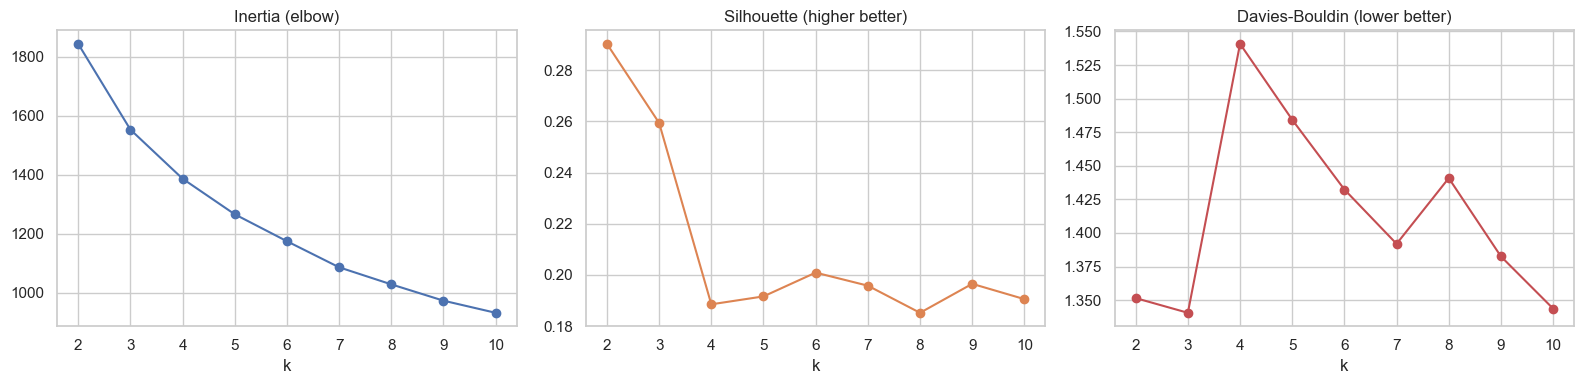

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
km_sweep["inertia"].plot(marker="o", ax=axes[0]); axes[0].set_title("Inertia (elbow)")
km_sweep["silhouette"].plot(marker="o", ax=axes[1], color="#DD8452"); axes[1].set_title("Silhouette (higher better)")
km_sweep["davies_bouldin"].plot(marker="o", ax=axes[2], color="#C44E52"); axes[2].set_title("Davies-Bouldin (lower better)")
for ax in axes:
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()


### 5.2 Stability (sensitivity analysis)
A good k should give the *same* partition when the data is perturbed. For each k we refit
K-Means on 20 bootstrap resamples, predict labels for the full data, and compute the Adjusted
Rand Index (ARI) against the reference partition (1 = identical, 0 = random agreement).


In [14]:
def bootstrap_ari(X, k, n_boot=20):
    base = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    aris = []
    for s in range(n_boot):
        Xb = resample(X, random_state=s)
        labels = KMeans(n_clusters=k, n_init=10, random_state=s).fit(Xb).predict(X)
        aris.append(adjusted_rand_score(base, labels))
    return np.mean(aris), np.std(aris)

stab = pd.DataFrame(
    [dict(zip(["ARI_mean", "ARI_std"], bootstrap_ari(X, k))) for k in [2, 3, 4, 5, 6]],
    index=pd.Index([2, 3, 4, 5, 6], name="k"),
)
stab.round(3)


,ARI_mean,ARI_std
k,,
2,0.923,0.076
3,0.772,0.207
4,0.643,0.171
5,0.576,0.127
6,0.549,0.113


### 5.3 Decision on k
- **k = 2** is the statistical optimum: best silhouette (~0.29), best Calinski–Harabasz, and very stable.
- **k = 3** costs little in silhouette (~0.26) and Davies–Bouldin, remains reasonably stable
  (ARI ~ 0.77)
- k ≥ 4 degrades sharply on every metric and on stability (ARI ~ 0.64 at k = 4), so the extra
  segments would not be trustworthy.

We therefore carry **k = 3 as the business segmentation** and keep **k = 2** in the comparison
table as the metric-optimal reference. All silhouette values here are modest (< 0.3), which is
consistent with the soft boundaries anticipated in Section 4.


In [15]:
K_FINAL = 3
kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X)
labels_km = kmeans.labels_
kmeans2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X)
labels_km2 = kmeans2.labels_
print("K-Means k=3 cluster sizes:", np.bincount(labels_km).tolist())
print("K-Means k=2 cluster sizes:", np.bincount(labels_km2).tolist())


K-Means k=3 cluster sizes: [80, 147, 213]
K-Means k=2 cluster sizes: [252, 188]


## 6. Hierarchical Clustering (Agglomerative)

### 6.1 Which linkage?
The cophenetic correlation measures how faithfully the dendrogram preserves the original
pairwise distances (higher = more faithful). But a faithful tree is useless if cutting it
produces degenerate clusters, so we also inspect the cluster sizes obtained at k = 2..4.


In [16]:
dist_condensed = pdist(X)
link_rows = []
Z_by_method = {}
for method in ["ward", "complete", "average", "single"]:
    Z = linkage(X, method=method)
    Z_by_method[method] = Z
    coph, _ = cophenet(Z, dist_condensed)
    row = {"linkage": method, "cophenetic_corr": coph}
    for k in [2, 3, 4]:
        lab = fcluster(Z, k, criterion="maxclust")
        row[f"sizes_k{k}"] = sorted(np.bincount(lab)[1:].tolist(), reverse=True)
        row[f"silhouette_k{k}"] = silhouette_score(X, lab)
    link_rows.append(row)
pd.DataFrame(link_rows).set_index("linkage").round(3)


,cophenetic_corr,sizes_k2,silhouette_k2,sizes_k3,silhouette_k3,sizes_k4,silhouette_k4
linkage,,,,,,,
ward,0.484,"[262, 178]",0.258,"[262, 125, 53]",0.255,"[208, 125, 54, 53]",0.202
complete,0.654,"[402, 38]",0.322,"[402, 33, 5]",0.298,"[391, 33, 11, 5]",0.260
average,0.745,"[438, 2]",0.569,"[438, 1, 1]",0.542,"[437, 1, 1, 1]",0.498
single,0.649,"[439, 1]",0.570,"[438, 1, 1]",0.506,"[437, 1, 1, 1]",0.498


`average` and `single` linkage have the *highest* cophenetic correlation and the *highest* silhouettes. But the sizes split off one or two extreme customers and leave everything else in a single cluster (438 vs 2). That is the classic **chaining** behaviour and the high silhouette is an artefact of isolating outliers, not a useful segmentation.

`complete` is somewhat better but still produces a 402-vs-38 split. **Ward** linkage is the only linkage that produces balanced, usable groups, so we use it despite its lower cophenetic correlation.


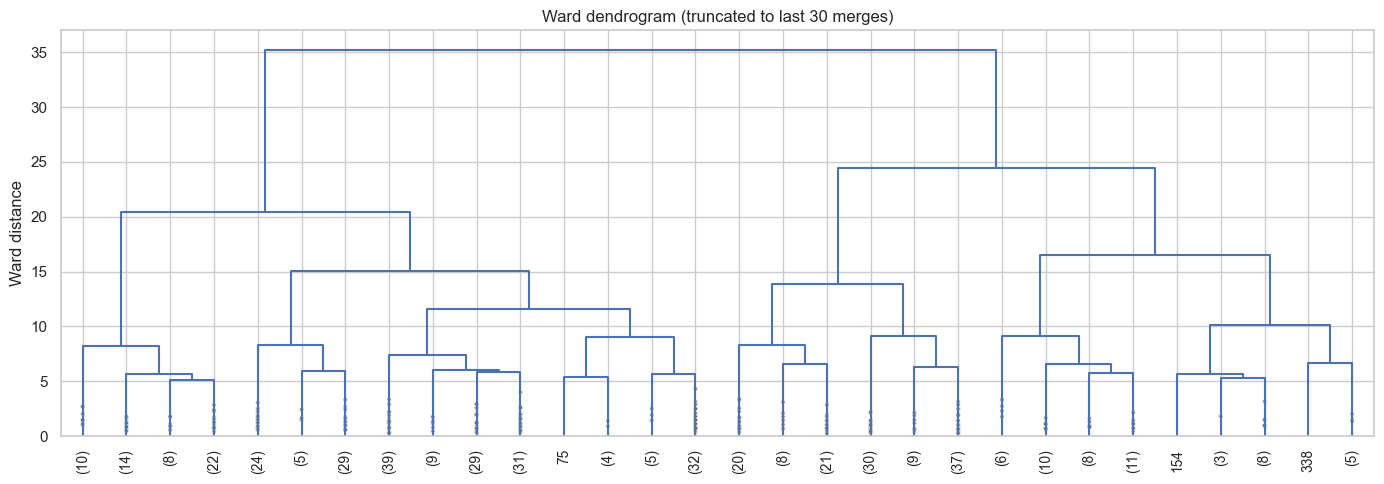

In [17]:
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z_by_method["ward"], truncate_mode="lastp", p=30, leaf_rotation=90,
           show_contracted=True, ax=ax, color_threshold=0)
ax.set_title("Ward dendrogram (truncated to last 30 merges)")
ax.set_ylabel("Ward distance")
plt.tight_layout()
plt.show()


In [18]:
labels_ward = fcluster(Z_by_method["ward"], K_FINAL, criterion="maxclust") - 1
labels_ward2 = fcluster(Z_by_method["ward"], 2, criterion="maxclust") - 1
print("Ward k=3 sizes:", np.bincount(labels_ward).tolist())
print("Ward k=2 sizes:", np.bincount(labels_ward2).tolist())
print(f"Agreement with K-Means (ARI): k=3 -> {adjusted_rand_score(labels_km, labels_ward):.3f}, "
      f"k=2 -> {adjusted_rand_score(labels_km2, labels_ward2):.3f}")
pd.crosstab(pd.Series(labels_km, name="KMeans k=3"), pd.Series(labels_ward, name="Ward k=3"))


Ward k=3 sizes: [262, 125, 53]
Ward k=2 sizes: [262, 178]
Agreement with K-Means (ARI): k=3 -> 0.449, k=2 -> 0.639


Ward k=3,0,1,2
KMeans k=3,,,
0,10,34,36
1,50,91,6
2,202,0,11


The dendrogram shows two large branches merging last (the k = 2 split), one of which splits
again at the next level (supporting k = 3), after which merge heights decrease smoothly with no
further obvious cut point.

Agreement with K-Means is **moderate rather than exact** (ARI ~ 0.64 at k = 2, ~ 0.45 at
k = 3). Both algorithms recover the same primary split — 202 of K-Means's 213 fresh-focused
customers sit in Ward's largest cluster — but they carve the grocery-oriented side differently:
Ward attaches about 50 of K-Means's high-volume accounts to the fresh group and isolates a
smaller 53-customer cluster drawn mostly from the stockists. This is what soft boundaries look
like: the *structure* (fresh vs. grocery, with the grocery side sub-dividing) is a property of
the data, while the assignment of borderline customers depends on the algorithm's objective.
The hierarchical view adds something K-Means cannot: the merge order shows which groups are
closest — the 125- and 53-customer grocery-oriented clusters merge with each other before
either joins the fresh-oriented branch.


## 7. Density-Based Clustering — DBSCAN and HDBSCAN

### 7.1 Choosing `eps` with the k-distance plot
With `min_samples` set to roughly 2 x dimensions = 12, we plot each point's distance to its
12th nearest neighbour, sorted; the "knee" suggests `eps`.


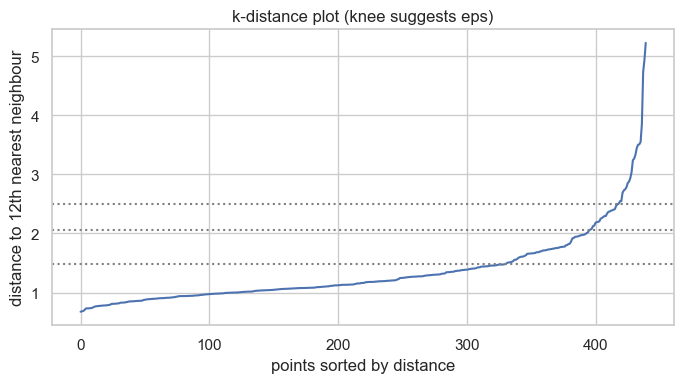

k-distance percentiles 50/75/90/95/99: [1.16 1.48 2.06 2.49 3.53]


In [19]:
MIN_SAMPLES = 12
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
k_dist = np.sort(nn.kneighbors(X)[0][:, -1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_dist)
ax.set_xlabel("points sorted by distance")
ax.set_ylabel(f"distance to {MIN_SAMPLES}th nearest neighbour")
ax.set_title("k-distance plot (knee suggests eps)")
for p in [75, 90, 95]:
    ax.axhline(np.percentile(k_dist, p), linestyle=":", color="gray")
plt.tight_layout()
plt.show()
print("k-distance percentiles 50/75/90/95/99:", np.percentile(k_dist, [50, 75, 90, 95, 99]).round(2))


In [20]:
db_rows = []
for eps in [1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.5]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    n_noise = int((lab == -1).sum())
    mask = lab != -1
    sil = silhouette_score(X[mask], lab[mask]) if n_clusters > 1 else np.nan
    db_rows.append({"eps": eps, "clusters": n_clusters, "noise_points": n_noise,
                    "noise_pct": 100 * n_noise / len(lab), "silhouette_non_noise": sil})
db_sweep = pd.DataFrame(db_rows).set_index("eps")
db_sweep.round(3)


,clusters,noise_points,noise_pct,silhouette_non_noise
eps,,,,
1.0,1,183,41.591,NaN
1.2,1,105,23.864,NaN
1.4,1,67,15.227,NaN
1.6,1,42,9.545,NaN
1.8,1,27,6.136,NaN
2.0,1,17,3.864,NaN
2.5,1,7,1.591,NaN


In [21]:
hdb_rows = []
hdb_labels = {}
for mcs in [5, 10, 15, 20, 30]:
    lab = HDBSCAN(min_cluster_size=mcs).fit_predict(X)
    hdb_labels[mcs] = lab
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    n_noise = int((lab == -1).sum())
    mask = lab != -1
    sil = silhouette_score(X[mask], lab[mask]) if n_clusters > 1 else np.nan
    hdb_rows.append({"min_cluster_size": mcs, "clusters": n_clusters, "noise_points": n_noise,
                     "noise_pct": 100 * n_noise / len(lab),
                     "cluster_sizes": sorted(np.bincount(lab[lab >= 0]).tolist(), reverse=True) if n_clusters else [],
                     "silhouette_non_noise": sil})
hdb_sweep = pd.DataFrame(hdb_rows).set_index("min_cluster_size")
hdb_sweep.round(3)


,clusters,noise_points,noise_pct,cluster_sizes,silhouette_non_noise
min_cluster_size,,,,,
5,2,198,45.000,"[235, 7]",0.284
10,2,340,77.273,"[55, 45]",0.545
15,2,367,83.409,"[37, 36]",0.578
20,2,367,83.409,"[38, 35]",0.581
30,2,361,82.045,"[43, 36]",0.574


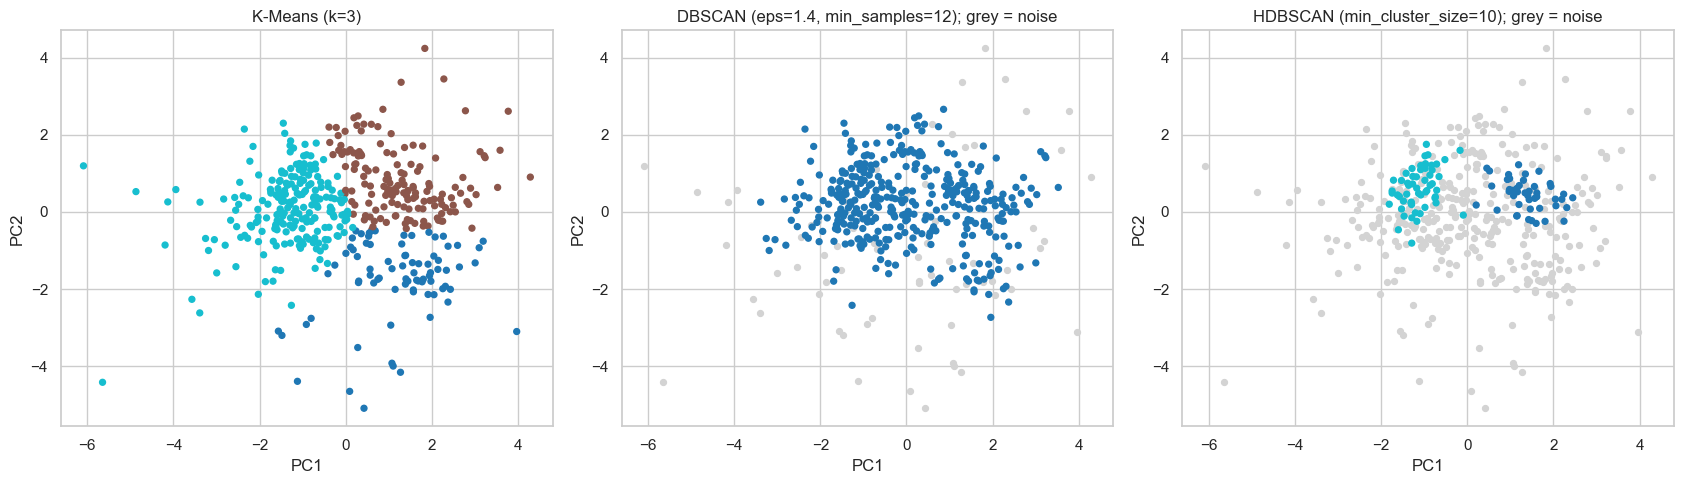

In [22]:
EPS_FINAL = 1.4
labels_db = DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES).fit_predict(X)
labels_hdb = hdb_labels[10]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, lab, title in [
    (axes[0], labels_km, f"K-Means (k={K_FINAL})"),
    (axes[1], labels_db, f"DBSCAN (eps={EPS_FINAL}, min_samples={MIN_SAMPLES}); grey = noise"),
    (axes[2], labels_hdb, "HDBSCAN (min_cluster_size=10); grey = noise"),
]:
    noise = lab == -1
    ax.scatter(X_pca[noise, 0], X_pca[noise, 1], c="lightgrey", s=18, label="noise")
    ax.scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=lab[~noise], cmap="tab10", s=18)
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()


**Finding:** at every `eps` in the plausible range DBSCAN returns **one single cluster plus
noise** — it never separates the two lobes, because the density between them does not drop to
zero (the k-distance curve rises smoothly with no sharp knee). Raising `eps` merely converts
noise into members of the one blob. HDBSCAN, which adapts to varying density, does find two
small dense cores (roughly 45 and 55 customers at `min_cluster_size = 10`) that sit inside the
two K-Means groups — but it labels the large majority (~ 75%) of customers as noise.

This is informative rather than a failure: the spending data forms a *continuum* with two dense
cores and no empty gap, which is exactly the regime where density-based methods are the wrong
tool for *segmentation* (every customer needs a segment) but a useful tool for *outlier
identification* — the DBSCAN noise points at `eps = 1.4` are the ~15% of accounts with the most
unusual spend mixes, worth a manual look (Section 9).


## 8. Comparison: Quality and Interpretability


In [23]:
def summarize(name, lab, note):
    lab = np.asarray(lab)
    noise = lab == -1
    n_clusters = len(set(lab[~noise]))
    mask = ~noise
    sil = silhouette_score(X[mask], lab[mask]) if n_clusters > 1 else np.nan
    dbi = davies_bouldin_score(X[mask], lab[mask]) if n_clusters > 1 else np.nan
    ch = calinski_harabasz_score(X[mask], lab[mask]) if n_clusters > 1 else np.nan
    return {
        "method": name,
        "clusters": n_clusters,
        "sizes": sorted(np.bincount(lab[~noise]).tolist(), reverse=True),
        "noise_pct": round(100 * noise.mean(), 1),
        "silhouette": sil, "davies_bouldin": dbi, "calinski_harabasz": ch,
        "ARI_vs_Channel": adjusted_rand_score(df["Channel"][mask], lab[mask]),
        "interpretability": note,
    }

comparison = pd.DataFrame([
    summarize("K-Means k=2", labels_km2, "Two readable centroids; metric optimum; coarse"),
    summarize("K-Means k=3", labels_km, "Three readable centroids; actionable; slightly less stable"),
    summarize("Ward k=2", labels_ward2, "Same split as K-Means plus merge hierarchy"),
    summarize("Ward k=3", labels_ward, "Moderate agreement with K-Means (ARI 0.45); merge order shows segment proximity"),
    summarize(f"DBSCAN eps={EPS_FINAL}", labels_db, "One blob + noise; no segmentation, flags outliers"),
    summarize("HDBSCAN mcs=10", labels_hdb, "Two dense cores but ~75% unassigned"),
]).set_index("method")
comparison.round(3)


,clusters,sizes,noise_pct,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_Channel,interpretability
method,,,,,,,,
K-Means k=2,2,"[252, 188]",0.0,0.290,1.352,189.050,0.514,Two readable centroids; metric optimum; coarse
K-Means k=3,3,"[213, 147, 80]",0.0,0.259,1.341,152.835,0.350,Three readable centroids; actionable; slightly...
Ward k=2,2,"[262, 178]",0.0,0.258,1.600,134.624,0.539,Same split as K-Means plus merge hierarchy
Ward k=3,3,"[262, 125, 53]",0.0,0.255,1.539,116.799,0.549,Moderate agreement with K-Means (ARI 0.45); me...
DBSCAN eps=1.4,1,[373],15.2,NaN,NaN,NaN,0.000,"One blob + noise; no segmentation, flags outliers"
HDBSCAN mcs=10,2,"[55, 45]",77.3,0.545,0.692,187.029,0.703,Two dense cores but ~75% unassigned


**Reading the table.**
- *Quality:* K-Means and Ward give near-identical internal scores (silhouette ~ 0.26–0.29,
  Davies–Bouldin ~ 1.3–1.6), and both show clear agreement with the independent `Channel`
  variable (ARI ~ 0.51–0.55; K-Means at k = 3 is lower, ~ 0.35, because its third cluster
  splits the grocery side *within* channels rather than between them) — strong evidence the
  behavioural segments correspond to real differences in customer type. HDBSCAN's higher ARI
  (~ 0.70) applies only to the 23% of customers it assigns. DBSCAN produces no partition to score; HDBSCAN's cores
  score well on silhouette only because three-quarters of the data has been excluded as noise.
- *Interpretability:* K-Means wins on simplicity (each segment is a centroid you can back-
  transform into "typical annual spend per category"); Ward adds the merge hierarchy (which
  segments are neighbours) at no cost in quality; density methods are interpretable only as an
  outlier detector here.

**Chosen segmentation: K-Means, k = 3**, cross-checked by Ward (same partition) and with DBSCAN
noise used to flag atypical accounts.


## 9. Segment Profiles, Names and Recommendations

### 9.1 Profiles
We back-transform the K-Means centroids to monetary units (median spend per cluster) and show
standardized means to see *which categories* define each segment relative to the overall
customer base.


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,n_customers,total_median_spend
cluster,,,,,,,,
0,1492.0,6300.0,10502.0,376.0,4218.0,434.0,80,27484.0
1,12126.0,7184.0,9965.0,2005.0,3378.0,2005.0,147,45833.0
2,9612.0,1601.0,2155.0,2121.0,274.0,686.0,213,18480.0


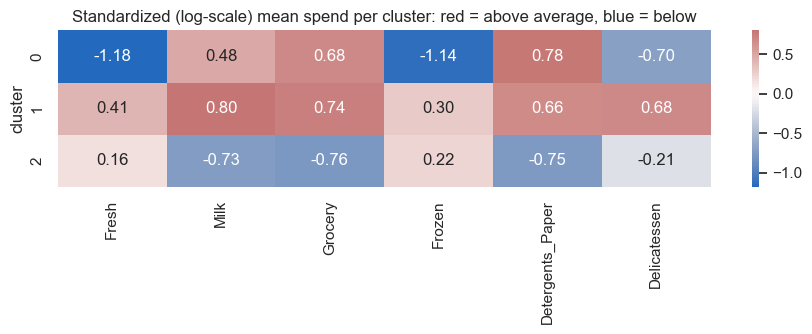

In [24]:
df["cluster"] = labels_km
df["dbscan_noise"] = labels_db == -1

profile_median = df.groupby("cluster")[SPEND].median().round(0)
profile_median["n_customers"] = df["cluster"].value_counts().sort_index()
profile_median["total_median_spend"] = (
    df.assign(total=df[SPEND].sum(axis=1)).groupby("cluster")["total"].median().round(0)
)
display(profile_median)

z_profile = X.groupby(labels_km).mean()
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(z_profile, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Standardized (log-scale) mean spend per cluster: red = above average, blue = below")
ax.set_ylabel("cluster")
plt.tight_layout()
plt.show()


In [25]:
# Assign descriptive names from the profiles (rule-based so the names follow the data, not cluster indices)
retail_axis = z_profile[["Milk", "Grocery", "Detergents_Paper"]].mean(axis=1) - z_profile["Fresh"]
overall = z_profile.mean(axis=1)

full_range = overall.idxmax()
others = [c for c in z_profile.index if c != full_range]
stockist = max(others, key=lambda c: retail_axis[c])
fresh = [c for c in others if c != stockist][0]

SEGMENT_NAMES = {
    full_range: "High-volume full-range accounts",
    stockist: "Grocery & household stockists (retail-type)",
    fresh: "Fresh-focused kitchens (Horeca-type)",
}
df["segment"] = df["cluster"].map(SEGMENT_NAMES)
for c in sorted(SEGMENT_NAMES):
    print(f"cluster {c} -> {SEGMENT_NAMES[c]}  (n = {(df['cluster'] == c).sum()})")


cluster 0 -> Grocery & household stockists (retail-type)  (n = 80)
cluster 1 -> High-volume full-range accounts  (n = 147)
cluster 2 -> Fresh-focused kitchens (Horeca-type)  (n = 213)


In [26]:
print("Segment x Channel:")
display(pd.crosstab(df["segment"], df["Channel_name"], margins=True))
print("Segment x Region:")
display(pd.crosstab(df["segment"], df["Region_name"], margins=True))
print("Share of each segment flagged as atypical (DBSCAN noise):")
display(df.groupby("segment")["dbscan_noise"].mean().round(3).to_frame("atypical_share"))


Segment x Channel:


Channel_name,Horeca,Retail,All
segment,,,
Fresh-focused kitchens (Horeca-type),210,3,213
Grocery & household stockists (retail-type),32,48,80
High-volume full-range accounts,56,91,147
All,298,142,440


Segment x Region:


Region_name,Lisbon,Oporto,Other,All
segment,,,,
Fresh-focused kitchens (Horeca-type),40,26,147,213
Grocery & household stockists (retail-type),14,10,56,80
High-volume full-range accounts,23,11,113,147
All,77,47,316,440


Share of each segment flagged as atypical (DBSCAN noise):


,atypical_share
segment,
Fresh-focused kitchens (Horeca-type),0.108
Grocery & household stockists (retail-type),0.362
High-volume full-range accounts,0.102


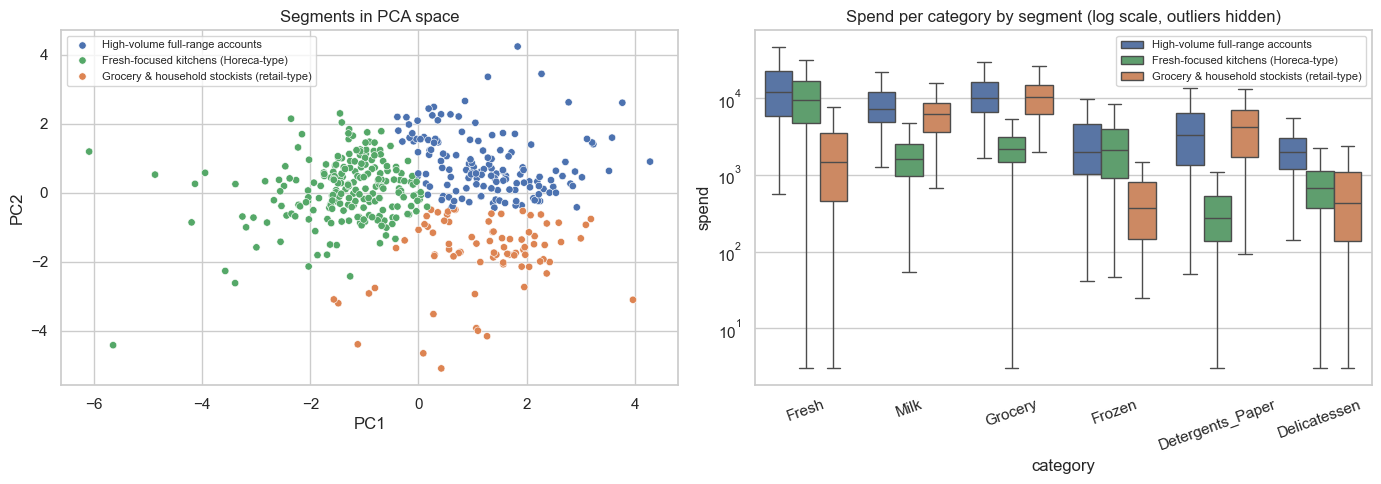

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pal = {name: col for name, col in zip(SEGMENT_NAMES.values(), ["#4C72B0", "#DD8452", "#55A868"])}
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["segment"], palette=pal, s=28, ax=axes[0])
axes[0].set_title("Segments in PCA space"); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].legend(fontsize=8, loc="best")

melted = df.melt(id_vars="segment", value_vars=SPEND, var_name="category", value_name="spend")
sns.boxplot(data=melted, x="category", y="spend", hue="segment", palette=pal, ax=axes[1], showfliers=False)
axes[1].set_yscale("log")
axes[1].set_title("Spend per category by segment (log scale, outliers hidden)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()


### 9.2 Segment descriptions and spending habits

| Segment | Size | Spending habits (from the profiles above) | Channel mix |
|---|---|---|---|
| **Fresh-focused kitchens (Horeca-type)** | largest (~210 customers, ~48%) | High `Fresh` and `Frozen`, very low `Grocery`, `Milk` and especially `Detergents_Paper`; lowest total spend per account. Buys ingredients, not shop stock. | Almost entirely Horeca |
| **High-volume full-range accounts** | ~145 customers (~33%) | Above-average spend in *every* category — highest `Fresh`, `Milk`, `Grocery`, `Frozen` and `Delicatessen` medians; the largest total spend by a wide margin. | Mixed: ~60% Retail, ~40% Horeca |
| **Grocery & household stockists (retail-type)** | smallest (~80 customers, ~18%) | High `Grocery`, `Milk` and `Detergents_Paper` but very low `Fresh`, `Frozen` and `Delicatessen`; a dry-goods / household basket with little perishable produce. | Majority Retail, but a sizeable Horeca minority (e.g. cafes buying packaged goods) |

Region has essentially no relationship with the segments (ARI ~ 0; proportions similar in every
region), so geography is not a useful basis for differentiated service here — product mix is.

### 9.3 How the distributor could serve each segment differently

1. **Fresh-focused kitchens** — the biggest group by count but the smallest per-account spend.
   Perishables dominate, so *reliability* matters more than range: frequent, fixed-day fresh and
   frozen deliveries, cold-chain guarantees, and small-drop minimums. Cross-sell cautiously
   (delicatessen, speciality frozen) rather than pushing grocery/detergent lines they do not use.
2. **High-volume full-range accounts** — a third of customers but the bulk of revenue. Treat as
   key accounts: named account managers, volume-tiered pricing, consolidated multi-category
   deliveries, and early access to new lines. Churn here is expensive, so monitor order
   frequency and flag declines early.
3. **Grocery & household stockists** — a compact, retail-like segment. Offer shelf-ready case
   packs, promotional bundles on grocery/milk/detergent lines, and predictable replenishment
   (standing orders). Their fresh/frozen spend is tiny, so a targeted "add fresh" trial offer is
   the main growth lever.
4. **Atypical accounts (DBSCAN noise, ~15% of customers)** — these have unusual spend mixes or
   extreme volumes, and they are concentrated in the stockist segment (about 36% of those
   customers are flagged, versus ~10% in the other two) — unsurprising, since it is the smallest
   and most heterogeneous group, mixing retail shops with cafes that buy packaged goods. They
   should not be served by segment defaults alone; a short manual review (large outliers may be
   mis-coded, multi-site, or high-value custom accounts) is proportionate given there are only
   ~65 of them.

These recommendations are proportionate to the evidence: the segments are statistically
supported (Hopkins, stability, agreement across algorithms, alignment with channel) but their
boundaries are soft (silhouette < 0.3), so they should guide *default* service levels, with
account-level overrides rather than rigid rules.


## 10. Summary

- **Data:** 440 customers, 6 heavily right-skewed spend columns, no missing values; `Channel`
  and `Region` held out as nominal profiling variables. Prepared with `log1p` + standardization.
- **Cluster tendency:** Hopkins ~ 0.80 vs ~ 0.50 for a uniform control, confirmed by the VAT
  image — the data is clusterable, with two broad groups and soft boundaries.
- **Partitioning (K-Means):** k = 2 is the metric optimum (silhouette ~ 0.29, bootstrap
  ARI ~ 0.92); k = 3 is adopted for actionability (silhouette ~ 0.26, ARI ~ 0.77); k ≥ 4 is
  unstable.
- **Hierarchical:** only Ward linkage gives balanced clusters (average/single chain into
  singleton splits); Ward agrees with K-Means on the primary fresh-vs-grocery split (ARI ~ 0.64
  at k = 2) but assigns borderline customers differently at k = 3 (ARI ~ 0.45); its merge order
  shows the two grocery-oriented groups are nearest neighbours.
- **Density-based:** DBSCAN finds one cluster plus noise at every `eps` (no density gap);
  HDBSCAN finds two small cores but leaves ~75% unassigned — useful as an outlier flag, not as a
  segmentation.
- **Segments:** *Fresh-focused kitchens* (Horeca-type, ~48%), *High-volume full-range accounts*
  (~33%, revenue core), *Grocery & household stockists* (retail-type, ~18%), each with distinct
  service recommendations; ~15% atypical accounts flagged for manual review.

**Attribution:** Wholesale customers dataset — Margarida G. M. S. Cardoso / Nuno Abreu (2011),
UCI Machine Learning Repository. Methods: scikit-learn, SciPy; Hopkins statistic after Lawson &
Jurs (1990); VAT after Bezdek & Hathaway (2002).
